In [3]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

sns.set_theme(style="whitegrid")

PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
sys.path.append(os.path.join(PROJECT_ROOT, "src"))
from harmonization import harmonize_pakistan, harmonize_arab5, HARMONIZED_FEATURE_COLS

with open(os.path.join(PROJECT_ROOT, "config", "config.yaml")) as f:
    config = yaml.safe_load(f)

SEED = config["seed"]
INTERIM_DIR = os.path.join(PROJECT_ROOT, config["paths"]["interim_dir"])
EXTERNAL_DIR = os.path.join(PROJECT_ROOT, config["paths"]["external_dir"])
TABLES_DIR = os.path.join(PROJECT_ROOT, config["paths"]["tables_dir"])
os.makedirs(EXTERNAL_DIR, exist_ok=True)

In [4]:
pk = pd.read_csv(os.path.join(INTERIM_DIR, "pakistan_interim.csv"))
ar = pd.read_csv(os.path.join(INTERIM_DIR, "arab5_interim.csv"))

text_cat_cols = ["Female Education", "Husband Education", "Working Status", "Previous Miscarriage",
                  "Sufficient Money for Basic Needs", "Current Appereance Acceptance",
                  "Male Gender Preference", "Gravida"]
for col in text_cat_cols:
    pk[col] = pk[col].astype(str).str.strip()
    pk[col] = pk[col].replace("nan", pd.NA)
pk["Current Appereance Acceptance"] = pk["Current Appereance Acceptance"].replace("YY", "Yes")
pk["Gravida"] = pk["Gravida"].replace("Multigravida+D1191", "Multigravida")

print("Pakistan:", pk.shape, "| Arab5:", ar.shape)

Pakistan: (14008, 28) | Arab5: (3569, 52)


In [5]:
pk_h = harmonize_pakistan(pk)
ar_h = harmonize_arab5(ar)

print("Pakistan harmonized:")
print(pk_h[HARMONIZED_FEATURE_COLS + ["y_depression"]].isna().sum())
print(f"\nArab5 harmonized (using dep_items_complete==True subset, per Phase 3 decision):")
ar_h_primary = ar_h[ar_h["dep_items_complete"] == True].copy()
print(ar_h_primary[HARMONIZED_FEATURE_COLS + ["y_depression"]].isna().sum())

Pakistan harmonized:
age_group           2
education_group     0
employed            0
financial_strain    4
first_pregnancy     0
y_depression        0
dtype: int64

Arab5 harmonized (using dep_items_complete==True subset, per Phase 3 decision):
age_group           0
education_group     0
employed            0
financial_strain    0
first_pregnancy     1
y_depression        0
dtype: int64


In [6]:
pk_h_clean = pk_h.dropna(subset=HARMONIZED_FEATURE_COLS + ["y_depression"]).reset_index(drop=True)
ar_h_clean = ar_h_primary.dropna(subset=HARMONIZED_FEATURE_COLS + ["y_depression"]).reset_index(drop=True)

print(f"Pakistan: {len(pk)} -> {len(pk_h_clean)} after dropping missing harmonized features")
print(f"Arab5 (primary subset): {len(ar_h_primary)} -> {len(ar_h_clean)} after dropping missing harmonized features")

pk_h_clean.to_csv(os.path.join(EXTERNAL_DIR, "pakistan_harmonized.csv"), index=False)
ar_h_clean.to_csv(os.path.join(EXTERNAL_DIR, "arab5_harmonized.csv"), index=False)
print(f"\nSaved to {EXTERNAL_DIR}")

Pakistan: 14008 -> 14002 after dropping missing harmonized features
Arab5 (primary subset): 1499 -> 1498 after dropping missing harmonized features

Saved to C:\maternal-mental-health-risk\data/external_validation


In [7]:
comparison_rows = []
for col in HARMONIZED_FEATURE_COLS:
    pk_dist = pk_h_clean[col].value_counts(normalize=True).round(4)
    ar_dist = ar_h_clean[col].value_counts(normalize=True).round(4)
    for level in set(pk_dist.index) | set(ar_dist.index):
        comparison_rows.append({
            "feature": col, "level": level,
            "pakistan_pct": pk_dist.get(level, 0.0) * 100,
            "arab5_pct": ar_dist.get(level, 0.0) * 100,
        })

comparison_df = pd.DataFrame(comparison_rows).sort_values(["feature", "level"]).reset_index(drop=True)
print(comparison_df)
comparison_df.to_csv(os.path.join(TABLES_DIR, "harmonization_distribution_comparison.csv"), index=False)

            feature              level  pakistan_pct  arab5_pct
0         age_group            35_plus         13.26      15.15
1         age_group           under_35         86.74      84.85
2   education_group    above_secondary         28.23      78.57
3   education_group  secondary_or_less         71.77      21.43
4          employed           employed         26.00      37.58
5          employed       not_employed         74.00      62.42
6  financial_strain          no_strain         49.01      39.39
7  financial_strain             strain         50.99      60.61
8   first_pregnancy    first_pregnancy         26.02      33.58
9   first_pregnancy          not_first         73.98      66.42


Saved figure: C:\maternal-mental-health-risk\reports\figures\cross_country\harmonized_feature_distributions.png


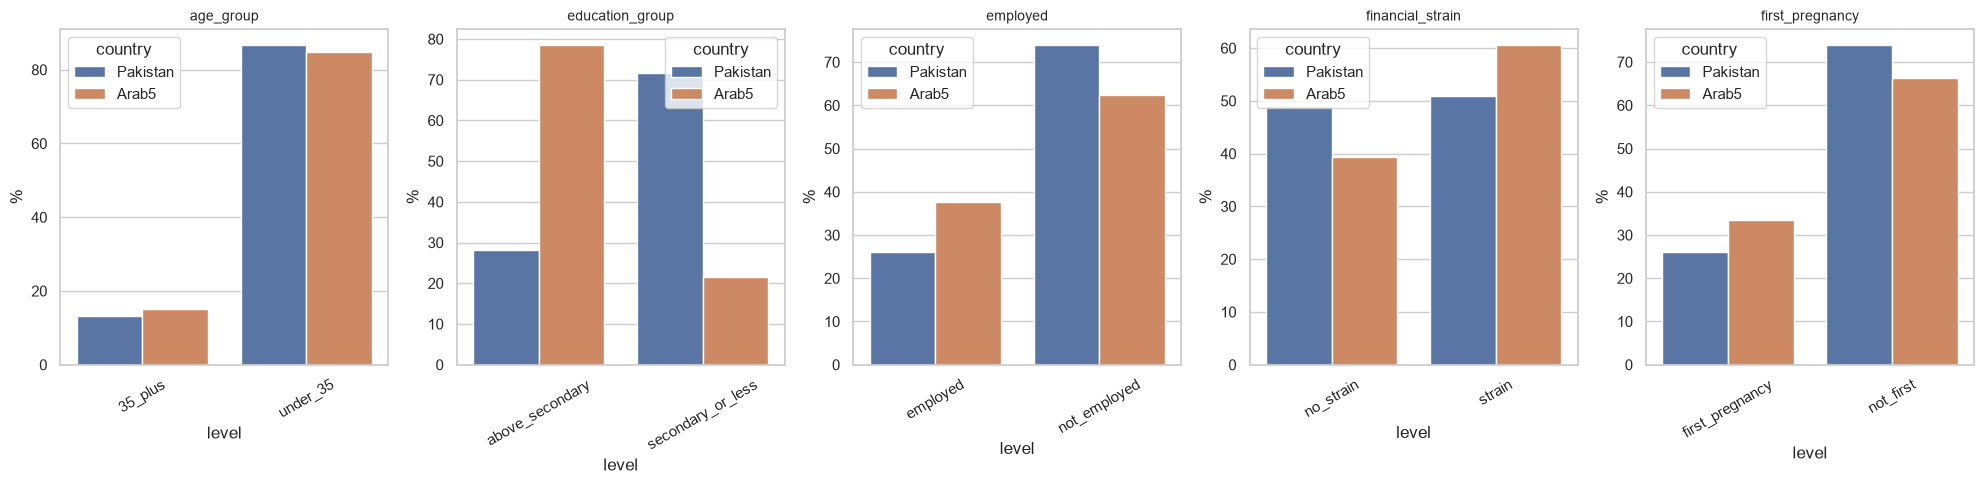

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, col in zip(axes, HARMONIZED_FEATURE_COLS):
    sub = comparison_df[comparison_df["feature"] == col].melt(
        id_vars="level", value_vars=["pakistan_pct", "arab5_pct"], var_name="country", value_name="pct")
    sub["country"] = sub["country"].map({"pakistan_pct": "Pakistan", "arab5_pct": "Arab5"})
    sns.barplot(data=sub, x="level", y="pct", hue="country", ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_ylabel("%")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()

from plotting_utils import save_fig
save_fig(fig, "harmonized_feature_distributions.png", PROJECT_ROOT, dataset="cross_country")
plt.show()

In [9]:
print(f"Pakistan depression prevalence: {pk_h_clean['y_depression'].mean():.4f} (n={len(pk_h_clean)})")
print(f"Arab5 depression prevalence: {ar_h_clean['y_depression'].mean():.4f} (n={len(ar_h_clean)})")

Pakistan depression prevalence: 0.6481 (n=14002)
Arab5 depression prevalence: 0.4566 (n=1498)
